# Vortex Notebook — an executable guide to periodic vortex dynamics

This notebook drives the tested `spectral_flow` package: it derives the
method, runs the Taylor–Green verification case against the analytic
solution, measures the RK4 time-convergence order, and evolves a nonlinear
cascade. The plots in the code cells are computed live when the notebook
runs; the closing animation is loaded from the higher-resolution recorded
run produced by `examples/run_verification.py` (not re-computed here).

Run from the repository root with the dependencies from
`requirements-dev.txt` installed (any environment with an `ipykernel`
`python3` kernel works):

```bash
python -m ipykernel install --user --name python3  # if no kernel yet
python examples/build_notebook.py --execute
```

Static export of the executed copy committed here is rendered directly
on GitHub.

## 1. Model and method

For velocity $\mathbf{u}=(u,v)$, vorticity $\omega=\partial_x v-\partial_y u$,
and kinematic viscosity $\nu$ on the periodic square $[0,2\pi)^2$:

$$\frac{\partial\omega}{\partial t} + \nabla\cdot(\mathbf{u}\,\omega) = \nu\nabla^2\omega,
\qquad \hat{\psi}=\frac{\hat{\omega}}{k^2}\ (k\neq 0),\quad
\hat{u}=ik_y\hat{\psi},\ \hat{v}=-ik_x\hat{\psi}.$$

The sign matters: $\omega=-\nabla^2\psi$ gives $\hat\psi=+\hat\omega/k^2$.
The nonlinear term is evaluated in conservative form and both it and the
solution are projected onto the strict band $|k_x|,|k_y|<N/3$, which makes
quadratic products alias-free on the retained band (an inclusive $N/3$
cutoff would fold boundary pairs back into the band). Time stepping is
classical RK4. The mean vorticity $\hat\omega(0,0)$ is an exactly conserved
passive constant; a periodic streamfunction cannot represent a uniform
background curl, so the recovered velocity is the curl-inverse of the
zero-mean part of $\omega$.

In [1]:
import pathlib, sys
import numpy as np
import matplotlib.pyplot as plt

NB_DIR = pathlib.Path('docs') if pathlib.Path('docs').exists() else pathlib.Path('.')
sys.path.insert(0, str(NB_DIR.resolve().parent))

from spectral_flow import SpectralVorticitySolver, taylor_green_vorticity
from spectral_flow.solver import taylor_green_velocity

plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.grid': False, 'axes.spines.top': False,
                     'axes.spines.right': False})
print('numpy', np.__version__)

numpy 2.1.3


## 2. Taylor–Green verification

The Taylor–Green vortex
$u=-\cos x\sin y\,f$, $v=\sin x\cos y\,f$, $\omega=2\cos x\cos y\,f$
with $f=e^{-2\nu t}$ is an exact solution (its nonlinear term vanishes
identically), with $E(t)=\tfrac14 e^{-4\nu t}$ and $Z(t)=\tfrac12 e^{-4\nu t}$.
It therefore verifies the Poisson inversion, the viscous operator, and the
time integrator simultaneously.

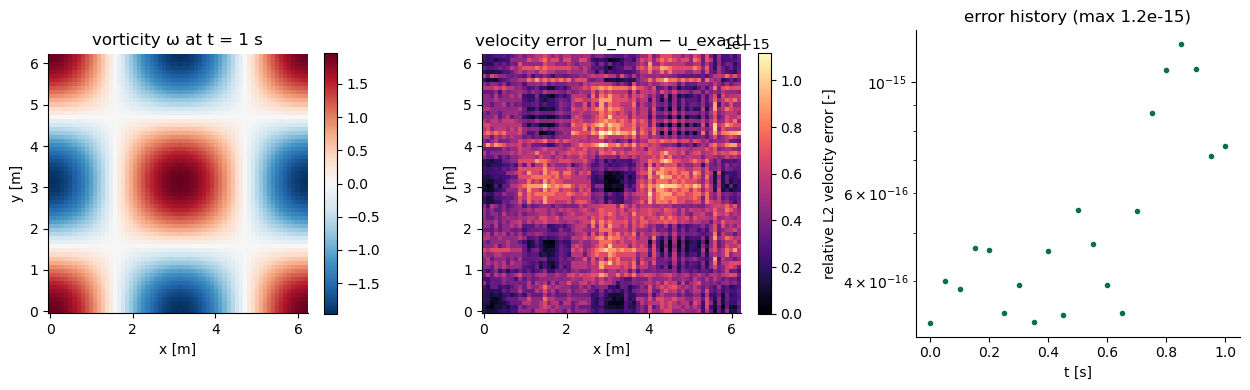

max relative L2 velocity error: 1.191e-15


In [2]:
n, nu, dt, t_end = 64, 0.01, 0.001, 1.0
solver = SpectralVorticitySolver(n=n, viscosity=nu)
x = np.arange(n) * (2*np.pi/n)
xx, yy = np.meshgrid(x, x, indexing='ij')
history = solver.integrate(taylor_green_vorticity(xx, yy), dt=dt,
                           nsteps=int(t_end/dt), sample_every=50)
t = np.array([h[0] for h in history])
E = np.array([solver.energy(h[1]) for h in history])
Z = np.array([solver.enstrophy(h[1]) for h in history])
err = np.array([solver.velocity_l2_error(h[1], tt) for tt, h in zip(t, history)])
E_exact = 0.25*np.exp(-4*nu*t); Z_exact = 0.5*np.exp(-4*nu*t)

wT = np.fft.ifft2(history[-1][1]).real
u_num, v_num = solver.velocity(history[-1][1])
u_ex, v_ex = taylor_green_velocity(xx, yy, t_end, nu)
err_field = np.sqrt((u_num-u_ex)**2 + (v_num-v_ex)**2)

fig, ax = plt.subplots(1, 3, figsize=(12.6, 4.0))
for a, field, title, cmap in ((ax[0], wT, 'vorticity ω at t = 1 s', 'RdBu_r'),
                              (ax[1], err_field, 'velocity error |u_num − u_exact|', 'magma')):
    pm = a.pcolormesh(x, x, field.T, cmap=cmap, shading='nearest')
    a.set_aspect('equal'); a.set_xlabel('x [m]'); a.set_ylabel('y [m]')
    a.set_title(title)
    fig.colorbar(pm, ax=a, shrink=0.85)
ax[2].semilogy(t, err, '.', color='#0b6e4f')
ax[2].set_xlabel('t [s]'); ax[2].set_ylabel('relative L2 velocity error [-]')
ax[2].set_title(f'error history (max {err.max():.1e})')
fig.tight_layout(); plt.show()
print(f'max relative L2 velocity error: {err.max():.3e}')

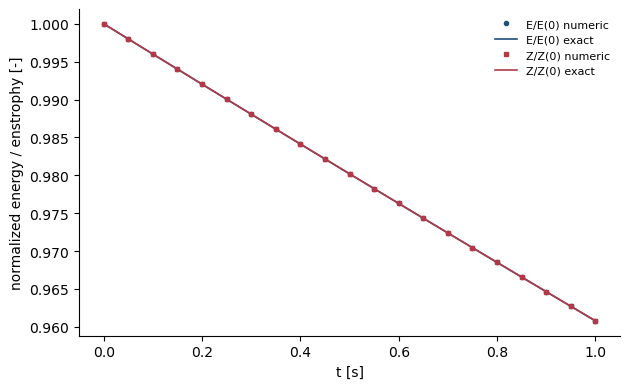

energy rel. deviation from exact: 1.33e-15
enstrophy rel. deviation from exact: 1.33e-15


In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(t, E/E[0], 'o', ms=3, color='#1f4e79', label='E/E(0) numeric')
ax.plot(t, E_exact/E_exact[0], '-', color='#1f4e79', lw=1.2, label='E/E(0) exact')
ax.plot(t, Z/Z[0], 's', ms=3, color='#b23a48', label='Z/Z(0) numeric')
ax.plot(t, Z_exact/Z_exact[0], '-', color='#b23a48', lw=1.2, label='Z/Z(0) exact')
ax.set_xlabel('t [s]'); ax.set_ylabel('normalized energy / enstrophy [-]')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
print(f'energy rel. deviation from exact: {abs(E[-1]/E_exact[-1]-1):.2e}')
print(f'enstrophy rel. deviation from exact: {abs(Z[-1]/Z_exact[-1]-1):.2e}')

## 3. RK4 time-convergence order

At $\nu=0.01$ the RK4 truncation error is far below the floating-point
roundoff floor, so the order must be measured in a strongly damped regime
($N=8$, $\nu=0.5$, $T=1$ s) where the temporal error is resolvable; the
finest step $\Delta t=0.025$ keeps the error near $10^{-9}$, well above
roundoff, so no saturation contaminates the slope.

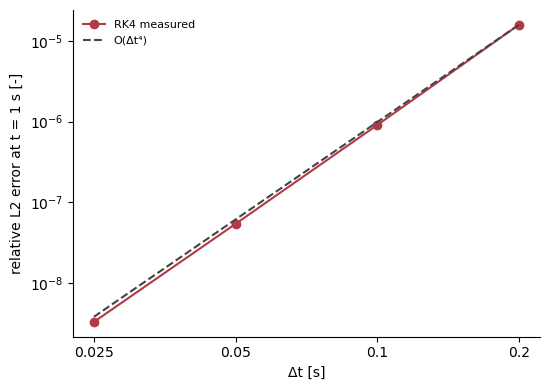

measured orders: [4.121 4.06  4.03 ]


In [4]:
conv_solver = SpectralVorticitySolver(n=8, viscosity=0.5)
w0c = taylor_green_vorticity(*np.meshgrid(np.arange(8)*(2*np.pi/8), np.arange(8)*(2*np.pi/8), indexing='ij'))
dts, errors = [], []
for dt in (0.2, 0.1, 0.05, 0.025):
    nsteps = int(round(1.0/dt))
    _, wh = conv_solver.integrate(w0c, dt=dt, nsteps=nsteps)[-1]
    dts.append(dt); errors.append(conv_solver.velocity_l2_error(wh, 1.0))
orders = np.log2(np.array(errors[:-1])/np.array(errors[1:]))

fig, ax = plt.subplots(figsize=(5.6, 4.0))
ax.loglog(dts, errors, 'o-', color='#b23a48', label='RK4 measured')
ax.loglog(dts, errors[0]*(np.array(dts)/dts[0])**4, '--', color='#444444', label='O(Δt⁴)')
ax.set_xticks(dts); ax.set_xticklabels([f'{d:g}' for d in dts]); ax.minorticks_off()
ax.set_xlabel('Δt [s]'); ax.set_ylabel('relative L2 error at t = 1 s [-]')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
print('measured orders:', np.round(orders, 3))

## 4. Nonlinear cascade (computed demonstration)

A band-limited large-scale initial condition plus small filtered noise
(seed 20261018) is evolved at low viscosity. Vortices merge, enstrophy
decays through the cascade, and the shell-summed energy statistic
$E(k)=\sum_{|k'|=k} \tfrac12(|\hat u|^2+|\hat v|^2)/N^4$ broadens toward
higher shells. By Parseval, $\sum_k E(k)$ equals the mean kinetic energy —
checked below. **There is no external reference for this case and none is
claimed**; it demonstrates the nonlinear machinery on a computed run.

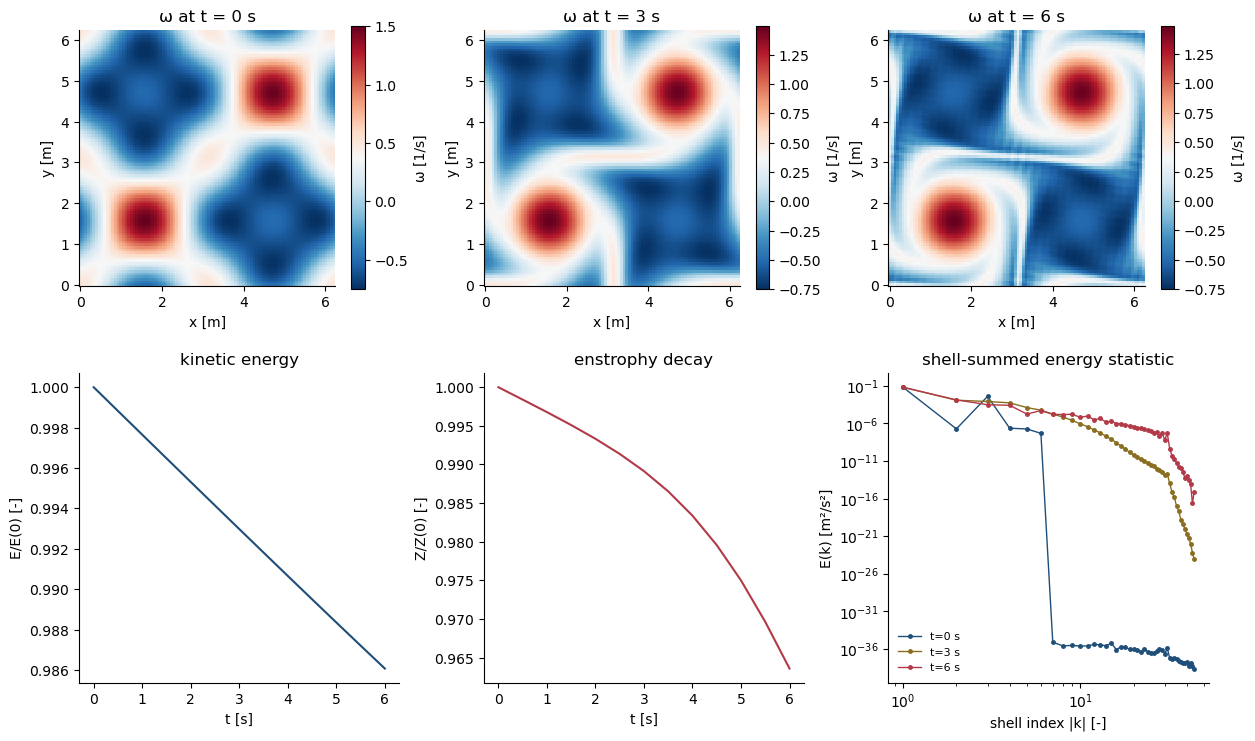

Parseval check: |Σ_k E(k) − E_mean| / E_mean = 0.00e+00


In [5]:
n2, nu2, dt2, t_end2 = 96, 5e-4, 0.005, 6.0
cas = SpectralVorticitySolver(n=n2, viscosity=nu2)
x2 = np.arange(n2)*(2*np.pi/n2)
xx2, yy2 = np.meshgrid(x2, x2, indexing='ij')
rng = np.random.default_rng(20261018)
w0 = np.sin(xx2)*np.sin(yy2) + 0.5*np.cos(2*xx2)*np.cos(2*yy2)
noise = np.fft.fft2(rng.standard_normal((n2, n2))) * cas.dealias_mask
noise[np.sqrt(cas.k2) > 6] = 0.0
w0 = w0 + 0.05*np.fft.ifft2(noise).real
hist2 = cas.integrate(w0, dt=dt2, nsteps=int(t_end2/dt2), sample_every=100)
t2 = np.array([h[0] for h in hist2])
E2 = np.array([cas.energy(h[1]) for h in hist2])
Z2 = np.array([cas.enstrophy(h[1]) for h in hist2])

def shell_energy(wh):
    uh, vh = cas.velocity_hat(wh)
    e = 0.5*(np.abs(uh)**2 + np.abs(vh)**2)/n2**4
    kr = np.rint(np.sqrt(cas.k2)).astype(int)
    return np.bincount(kr.ravel(), weights=e.ravel())

snaps = [np.fft.ifft2(hist2[i][1]).real for i in (0, len(hist2)//2, -1)]
specs = [shell_energy(hist2[i][1]) for i in (0, len(hist2)//2, -1)]
parseval_gap = abs(specs[-1].sum() - E2[-1]) / E2[-1]

fig, ax = plt.subplots(2, 3, figsize=(12.6, 7.6))
for a, w, tt in zip(ax[0], snaps, ('0', '3', '6')):
    pm = a.pcolormesh(x2, x2, w.T, cmap='RdBu_r', shading='nearest')
    a.set_aspect('equal'); a.set_xlabel('x [m]'); a.set_ylabel('y [m]')
    a.set_title(f'ω at t = {tt} s')
    fig.colorbar(pm, ax=a, shrink=0.85, label='ω [1/s]')
ax[1,0].plot(t2, E2/E2[0], color='#1f4e79'); ax[1,0].set_xlabel('t [s]')
ax[1,0].set_ylabel('E/E(0) [-]'); ax[1,0].set_title('kinetic energy')
ax[1,1].plot(t2, Z2/Z2[0], color='#b23a48'); ax[1,1].set_xlabel('t [s]')
ax[1,1].set_ylabel('Z/Z(0) [-]'); ax[1,1].set_title('enstrophy decay')
kk = np.arange(len(specs[-1]))
for spec, tt, c in zip(specs, ('0','3','6'), ('#1f4e79', '#8a6d1f', '#b23a48')):
    pos = spec > 0
    ax[1,2].loglog(kk[pos], spec[pos], 'o-', ms=2.5, lw=1.0, color=c, label=f't={tt} s')
ax[1,2].set_xlabel('shell index |k| [-]'); ax[1,2].set_ylabel('E(k) [m²/s²]')
ax[1,2].set_title('shell-summed energy statistic'); ax[1,2].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
print(f'Parseval check: |Σ_k E(k) − E_mean| / E_mean = {parseval_gap:.2e}')

## 5. Recorded vorticity animation

The full-resolution (N=128, 8 s, 41-frame) animation produced by
`examples/run_verification.py` (the committed reproduction script):

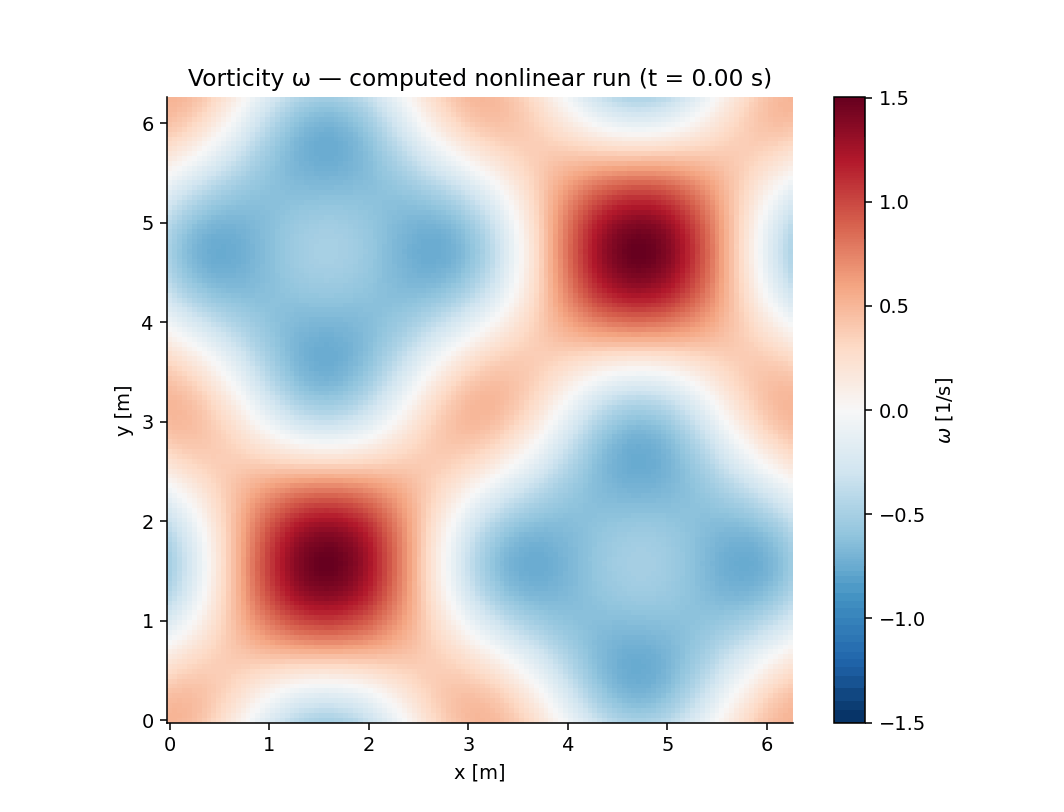

In [6]:
from IPython.display import Image
Image(filename=str(NB_DIR / 'results' / 'vorticity_evolution.gif'))

## 6. Explore your own parameters

Edit and re-run the next cell: resolution `n_exp`, viscosity `nu_exp`,
end time `t_exp`, and any initial vorticity field. Keep the explicit
stability bounds in mind: $\nu\,2(N/2)^2\Delta t \lesssim 2.8$ and
$\max|u|\,\Delta t/\Delta x \lesssim 1$.

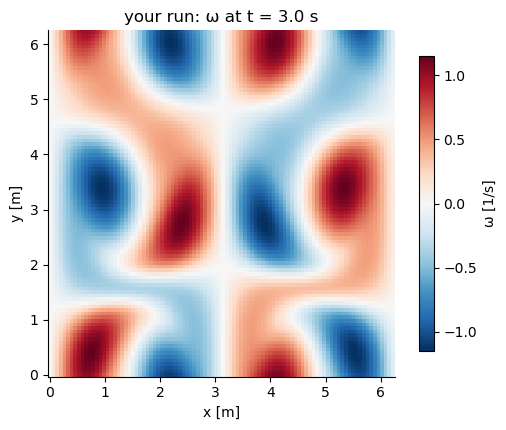

In [7]:
n_exp, nu_exp, t_exp = 96, 2e-3, 3.0
dt_exp = 0.002
exp_solver = SpectralVorticitySolver(n=n_exp, viscosity=nu_exp)
xe = np.arange(n_exp)*(2*np.pi/n_exp)
xxe, yye = np.meshgrid(xe, xe, indexing='ij')
w0_exp = np.sin(2*xxe)*np.cos(yye) + 0.4*np.sin(xxe)*np.sin(3*yye)
hexp = exp_solver.integrate(w0_exp, dt=dt_exp, nsteps=int(t_exp/dt_exp), sample_every=200)
fig, ax = plt.subplots(figsize=(5.6, 4.4))
pm = ax.pcolormesh(xe, xe, np.fft.ifft2(hexp[-1][1]).real.T, cmap='RdBu_r', shading='nearest')
ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.set_title(f'your run: ω at t = {hexp[-1][0]:.1f} s')
fig.colorbar(pm, ax=ax, shrink=0.85, label='ω [1/s]')
fig.tight_layout(); plt.show()

## 7. What this establishes — and what it does not

Verified here: exact analytic Taylor–Green decay to the roundoff floor at
the tested parameters, RK4 order ≈ 4 in a resolvable regime, Parseval
closure of the shell statistic, and a stable computed nonlinear cascade.
The test suite adds machine-precision divergence freedom, curl round trips,
and an independent 3/2-rule padded-reference alias check.

Not established: turbulence-statistics validation, high-Reynolds studies,
or agreement with experiments. The Taylor–Green case verifies the linear
machinery exactly (its nonlinear term is identically zero); nonlinear
correctness rests on the padded reference, not on an external
turbulent-flow benchmark. See `docs/verification.md` for details.